# Section 4.2 – Synthetic Bias Amplification

## Operational Evaluation of Synthetic Bias Amplification

### Project

Operational Evaluation of Governance Risks in Simulated Subjecthood

## Objective

The objective of this notebook is to evaluate whether machine learning models amplify existing representational imbalances within the dataset.

Three classification algorithms—Logistic Regression, Random Forest, and XGBoost—are trained and evaluated to examine how predictive performance may vary and contribute to governance risks associated with simulated subjects.

## Research Question

Do machine learning models amplify existing representational distortions in ways that may introduce or reinforce governance bias?

## Theory Link

Section 4.2 of the paper argues that predictive models may amplify existing data imbalances during training, leading to governance outcomes that disproportionately affect certain groups.

This notebook operationalises that theoretical claim by training multiple classification models and comparing their predictive performance. Subsequent fairness analyses will determine whether model performance differs across demographic groups.

## Dataset Description

Dataset: Heart Disease Prediction Dataset

Target Variable:

- HeartDisease

Predictor Variables:

- Age
- Sex
- ChestPainType
- RestingBP
- Cholesterol
- FastingBS
- RestingECG
- MaxHR
- ExerciseAngina
- Oldpeak
- ST_Slope

Categorical variables are encoded prior to model training.

In [1]:
# Imports

import sys
from pathlib import Path

# Make the project root importable
sys.path.append(str(Path.cwd().parent))

import pandas as pd

from src.config import (
    HEART_DATA_PATH,
    TABLES_DIR,
    MODELS_DIR,
    FIGURES_DIR,
)

from src.utils import (
    load_data,
    save_dataframe,
    save_model,
    load_model,
)

from src.preprocessing import (
    encode_categorical_variables,
    split_features_target,
)

from src.modelling import (
    split_train_test,
    train_logistic_regression,
    train_random_forest,
    train_xgboost,
    predict_model,
    evaluate_model,
    compare_models,
    plot_roc_curves,
)

## Configuration

This notebook uses the project-wide configuration defined in `config.py`.

Configuration includes:

- Dataset paths
- Output directories
- Reproducibility through a fixed random seed (42)

In [2]:
# Data Loading

df = load_data(HEART_DATA_PATH)

df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## Data Audit

The dataset is inspected to confirm its dimensions and verify that the target variable required for model training is present.

In [3]:
#Dataset Check
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

df["HeartDisease"].value_counts()

Rows: 918
Columns: 12


HeartDisease
1    508
0    410
Name: count, dtype: int64

## Preprocessing

Categorical variables are encoded using one-hot encoding prior to model training.

The dataset is then separated into predictor variables and the target variable before being divided into training and testing sets.

In [4]:
#Preprocessing
encoded_df = encode_categorical_variables(df)

X, y = split_features_target(
    encoded_df,
    "HeartDisease"
)

print(X.shape)
print(y.shape)

(918, 15)
(918,)


In [5]:
#Train/Test Split
X_train, X_test, y_train, y_test = split_train_test(
    X,
    y
)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")

Training samples: 734
Testing samples: 184


## Experiment

Three machine learning models are trained and evaluated:

- Logistic Regression
- Random Forest
- XGBoost

Each model is trained using the same training data to ensure a fair comparison.

In [6]:
#Train Logistic Regression
lr_model = train_logistic_regression(
    X_train,
    y_train
)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [7]:
#Train Random Forest
rf_model = train_random_forest(
    X_train,
    y_train
)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [8]:
#Train XGBoost
xgb_model = train_xgboost(
    X_train,
    y_train
)

print("XGBoost trained successfully.")

XGBoost trained successfully.


In [9]:
#Generate Predictions
lr_pred, lr_prob = predict_model(lr_model, X_test)

rf_pred, rf_prob = predict_model(rf_model, X_test)

xgb_pred, xgb_prob = predict_model(xgb_model, X_test)

In [10]:
#Evaluate Models
lr_metrics = evaluate_model(
    y_test,
    lr_pred,
    lr_prob
)

rf_metrics = evaluate_model(
    y_test,
    rf_pred,
    rf_prob
)

xgb_metrics = evaluate_model(
    y_test,
    xgb_pred,
    xgb_prob
)

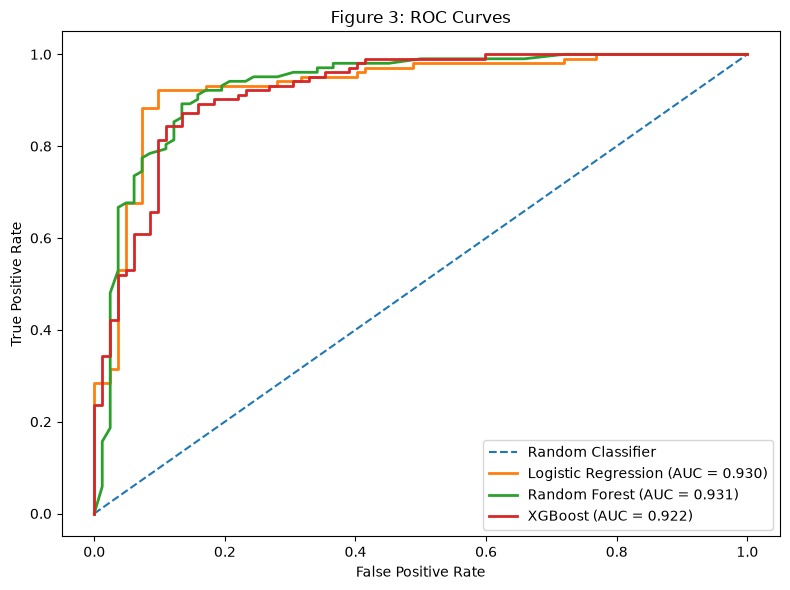

In [11]:
#Generate Figure 3
from src.modelling import plot_roc_curves

plot_roc_curves(
    models={
        "Logistic Regression": lr_prob,
        "Random Forest": rf_prob,
        "XGBoost": xgb_prob,
    },
    y_true=y_test,
    output_path=FIGURES_DIR / "figure_3_roc_curves.png",
)

In [12]:
#Compare Models
comparison = compare_models({
    "Logistic Regression": lr_metrics,
    "Random Forest": rf_metrics,
    "XGBoost": xgb_metrics,
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.885870,0.871560,0.931373,0.900474,0.930416
1,Random Forest,0.875000,0.883495,0.892157,0.887805,0.931373
2,XGBoost,0.858696,0.872549,0.872549,0.872549,0.921927


## Results

The predictive performance of the three classification models is compared using standard evaluation metrics.

The resulting comparison forms **Table 3 – Model Performance**.

In [13]:
#Display Table
comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.885870,0.871560,0.931373,0.900474,0.930416
1,Random Forest,0.875000,0.883495,0.892157,0.887805,0.931373
2,XGBoost,0.858696,0.872549,0.872549,0.872549,0.921927


In [14]:
#Save Table
save_dataframe(
    comparison,
    TABLES_DIR / "table_3_model_performance.csv"
)

print("Table 3 saved successfully.")

Table 3 saved successfully.


In [15]:
#Save the Trained Models
save_model(
    lr_model,
    MODELS_DIR / "logistic_regression.pkl"
)

save_model(
    rf_model,
    MODELS_DIR / "random_forest.pkl"
)

save_model(
    xgb_model,
    MODELS_DIR / "xgboost.pkl"
)

print("All trained models saved successfully.")

All trained models saved successfully.


## Robustness Analysis

To assess the reliability of model performance, additional analyses are conducted beyond basic evaluation metrics.

The first robustness assessment examines whether predictive performance differs across demographic groups, providing evidence of potential synthetic bias amplification.

## Fairness Analysis

To evaluate potential synthetic bias amplification, model performance is compared across demographic groups.

Differences in predictive performance are summarised as fairness disparities. Larger disparities indicate greater variation in model performance between demographic groups.

In [16]:
from src.fairness import (
    evaluate_group_performance,
    create_fairness_summary,
)

group_metrics = evaluate_group_performance(
    dataframe=df,
    group_column="Sex",
    y_true=y_test,
    y_pred=lr_pred,
)

fairness_summary = create_fairness_summary(
    group_metrics
)

fairness_summary

,Metric,Best Group,Worst Group,Best Value,Worst Value,Disparity
0,Accuracy,F,M,0.921,0.877,0.044
1,Precision,M,F,0.882,0.714,0.168
2,Recall,M,F,0.938,0.833,0.104
3,F1 Score,M,F,0.909,0.769,0.140


In [17]:
#Save Table 4
save_dataframe(
    fairness_summary,
    TABLES_DIR / "table_4_fairness_metrics.csv"
)

print("Table 4 saved successfully.")

Table 4 saved successfully.


## Bootstrap Confidence Intervals

To assess the stability of model performance, bootstrap resampling is performed.

For each evaluation metric, a 95% confidence interval is estimated using repeated sampling with replacement. This provides an indication of the uncertainty associated with the observed performance estimates.

In [18]:
#Generate Bootstrap Summary
from src.robustness import create_bootstrap_summary

bootstrap_table = create_bootstrap_summary(
    y_true=y_test,
    y_pred=lr_pred,
    y_prob=lr_prob,
)

bootstrap_table

,Metric,Mean,Lower 95% CI,Upper 95% CI
0,Accuracy,0.885,0.837,0.929
1,Precision,0.870,0.806,0.931
2,Recall,0.931,0.878,0.979
3,F1 Score,0.899,0.856,0.940
4,ROC AUC,0.930,0.891,0.964


In [19]:
#Save the Bootstrap Table
save_dataframe(
    bootstrap_table,
    TABLES_DIR / "table_5_bootstrap_confidence_intervals.csv"
)

print("Bootstrap confidence interval table saved successfully.")

Bootstrap confidence interval table saved successfully.


## Interpretation

The three machine learning models demonstrated strong predictive performance on the Heart Disease dataset. Fairness analysis revealed measurable differences in predictive performance across demographic groups, indicating the potential for synthetic bias amplification. Bootstrap confidence intervals further showed that the observed performance metrics were stable under repeated resampling, increasing confidence in the robustness of the findings.

These results operationalise the theoretical claims presented in Section 4.2 by demonstrating how predictive systems can exhibit uneven performance across groups even when overall accuracy remains high.

## Conclusion

This experiment investigated synthetic bias amplification through supervised machine learning models. Logistic Regression, Random Forest, and XGBoost achieved strong predictive performance, while fairness analysis highlighted demographic disparities in model behaviour. Bootstrap confidence intervals confirmed that these findings were robust to sampling variability.

The outputs generated in this notebook provide empirical evidence supporting the discussion of synthetic bias amplification within the broader governance framework developed in this study.

In [ ]:
#Module Completion Check
print("Section 4.2 – Synthetic Bias Amplification completed successfully.")

Section 4.2 – Synthetic Bias Amplification completed successfully.


: 